In [3]:
import sys
sys.path.append("..")

from utils import *

# Normale verdeling

## Kansen berekenen met een gegeven normale verdeling $N(\mu, \sigma)$

In [38]:
def compute_probabilities(left=None, right=None, mu=0, sigma=1):
    # Kansberekening
    print(left, right)
    if left is not None and right is not None:
        assert left <= right
        print(f"$P({left} \\leq X \\leq {right}) = {(norm.cdf(right, mu, sigma) - norm.cdf(left, mu, sigma)):.4f}$")
        return
    elif left is not None:
        print(f"$P(X \\geq {left}) = {(1 - norm.cdf(left, mu, sigma)):.4f}$")
        return
    else:
        print(f"$P(X \\leq {right}) = {norm.cdf(right, mu, sigma):.4f}$")
        return

compute_probabilities(left=0, right=1, mu=0, sigma=1)

0 1
$P(0 \leq X \leq 1) = 0.3413$


In [6]:
# Normale verdeling
def draw_normal_probabilities(mu=0, sigma=1, left=None, right=None, width=8, height=5, filename=None):
    variable_name = "Z" if mu == 0 and sigma == 1 else "X"
    x = np.linspace(mu - 4*sigma, mu + 4*sigma, 1_000)
    y = norm.pdf(x, mu, sigma)

    # Kansberekening
    if left and right:
        assert left <= right
        prob = pretty_print(norm.cdf(right, mu, sigma) - norm.cdf(left, mu, sigma))
        mask = ((x >= left) & (x <= right))
        label = f"$P({left} \\leq {variable_name} \\leq {right}) \\approx {prob}$" 
    elif left:
        prob = pretty_print(1 - norm.cdf(left, mu, sigma))
        mask = (x >= left)
        label = f"$P({variable_name} \\geq {left}) \\approx {prob}$"
    else:
        prob = pretty_print(norm.cdf(right, mu, sigma))
        mask = (x <= right)
        label = f"$P({variable_name} \\keq {right}) \\approx {prob}$"

    # Plot
    fig, ax = plt.subplots(figsize=(width, height))
    ax.plot(x, y, color=primary_plot_color)
    ax.fill_between(x, y, where=mask, color=primary_plot_color, alpha=opacity_level, label=label)
    if left:
        ax.plot([left, left], [0, norm.pdf(left, mu, sigma)], color=primary_plot_color, linestyle='--')
    if right:
        ax.plot([right, right], [0, norm.pdf(right, mu, sigma)], color=primary_plot_color, linestyle='--')

    if mu == 0 and sigma == 1:
        ax.set_title(f'Standaardnormale verdeling ${variable_name} \\sim N(\\mu={mu}, \\sigma={sigma})$')
        ax.set_xlabel('$z$')
        ax.set_ylabel('Kansdichtheidsfunctie $f(z)$')
    else:
        ax.set_title(f'Normale verdeling ${variable_name} \\sim N(\\mu={mu}, \\sigma={sigma})$')
        ax.set_xlabel('$x$')
        ax.set_ylabel('Kansdichtheidsfunctie $f(x)$')
    
    plt.legend()
    plt.tight_layout()
    plt.savefig(filename)

## Grenswaardes berekenen bij een gegeven normale verdeling $N(\mu, \sigma)$ en kans $p$

In [16]:
def compute_boundary_values(sample_mean, std, n, confidence, tail="center"):
    if tail == "left":
        g = norm.ppf(confidence, sample_mean, std / np.sqrt(n))
        print(f"{g:.4f}")
    elif tail == "center":
        g1 = norm.ppf(confidence/2, sample_mean, std / np.sqrt(n))
        g2 = norm.ppf(1-confidence/2, sample_mean, std / np.sqrt(n))
        print(f"{g1:.4f}, {g2:.4f}")
    elif tail == "right":
        g = norm.ppf(1-confidence, sample_mean, std / np.sqrt(n))
        print(f"{g:.4f}")

984.5051, 1015.4949
990.2002, 1009.7998
979.6363, 1020.3637
987.1209, 1012.8791


In [8]:
# Normale verdeling
def draw_boundary_values(mu=0, sigma=1, prob=0.5, tail="left", filename=None):
    variable_name = "Z" if mu == 0 and sigma == 1 else "X"
    xmin, xmax = mu - 4 * sigma, mu + 4 * sigma
    x = np.linspace(xmin, xmax, 1_000)
    y = norm.pdf(x, mu, sigma)

    # bereken de grenswaarden
    if tail == "left":
        g = norm.ppf(prob, mu, sigma)
        label = f"Grenswaarde: $g \\approx {pretty_print(g)}$"
        mask = (x <= g)
        title = f"Grenswaarde $g$ waarvoor geldt $P({variable_name} \\leq g) = {prob}$"
    elif tail == "center":
        g1 = norm.ppf(prob/2, mu, sigma)
        g2 = norm.ppf(1-prob/2, mu, sigma)
        label1 = f"$g_1 \\approx {pretty_print(g1)}$"
        label2 = f"$g_2 \\approx {pretty_print(g2)}$"
        mask = ((x >= g1)&(x<=g2))
        title = f"Grenswaarden $g_1$ en $g_2$ waarvoor geldt $P(g_1 \\leq {variable_name} \\leq g_2) = {prob}$"
    elif tail == "right":
        g = norm.ppf(1-prob, mu, sigma)
        label = f"Grenswaarde: $g \\approx {pretty_print(g)}$"
        mask = (x >= g)
        title = f"Grenswaarde $g$ waarvoor geldt $P({variable_name} \\geq g) = {prob}$"
    else:
        raise ValueError("De opgegeven optie voor de parameter 'tail' bestaat niet. Probeer opnieuw.")

    # Plot
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(x, y)
    ax.fill_between(x, y, where=mask, color=primary_plot_color, alpha=opacity_level)

    ymin, ymax = ax.get_ylim()
    ytext, offset = get_y_annotation(ax)
    ax.set_ylim(ymin - 2 * offset, ymax)
    
    if tail == "left" or tail == "right":
        ax.plot([g, g], [0, norm.pdf(g, mu, sigma)], color=primary_plot_color, linestyle='--', label=label)
        ax.text(g, ymin - offset, "$g$", color=primary_plot_color, ha="center", va="center")
    else:
        ax.plot([g1, g1], [0, norm.pdf(g1, mu, sigma)], color=primary_plot_color, linestyle='--', label=label1)
        ax.plot([g2, g2], [0, norm.pdf(g2, mu, sigma)], color=primary_plot_color, linestyle='--', label=label2)
        ax.text(g1, ytext, "$g_1$", color=primary_plot_color, ha="center", va="center")
        ax.text(g2, ytext, "$g_2$", color=primary_plot_color, ha="center", va="center")
    
    ax.set_title(title)
    ax.set_xlabel('$x$')
    ax.set_ylabel('Kansdichtheidsfunctie $f(x)$')
    
    ax.legend()
    plt.tight_layout()
    plt.savefig(filename)

### Voorbeeld gebruik

AttributeError: 'NoneType' object has no attribute 'write'

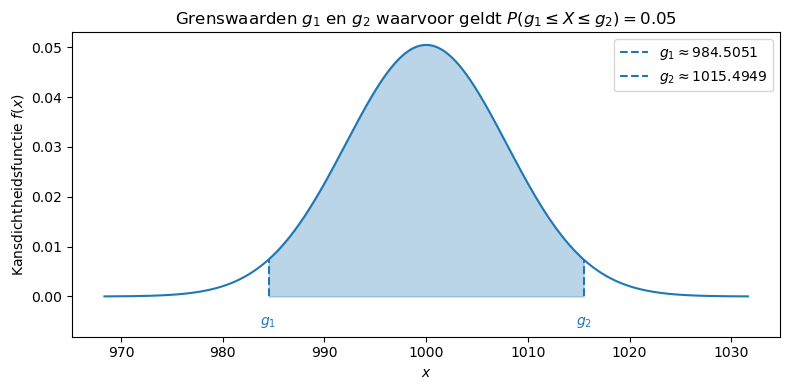

In [10]:
draw_normal_probabilities(mu=0, sigma=1, left=-1, right=1, filename="test_normal_prob.png")
draw_boundary_values(mu=58, sigma=16, prob=0.3, tail="center", filename="test_normal_boundary.png")